# Pertemuan 13 — Perbandingan dan Evaluasi
## Proyek Akhir Klasifikasi: k-NN dan Naive Bayes

Pembelajaran Mesin INF62325 · S1 Informatika · UIN Siber Syekh Nurjati Cirebon

### Tujuan pertemuan ini

Menentukan model mana yang lebih baik dengan cara yang sah, lalu menafsirkan
hasilnya. Tidak ada model yang dilatih ulang di sini.

### Luaran yang dikumpulkan

| Luaran | Bentuk |
| --- | --- |
| Tabel perbandingan validasi silang | tercetak di notebook |
| Dua confusion matrix | gambar di notebook |
| Tabel biaya komputasi | tercetak di notebook |
| Satu paragraf interpretasi | ditulis di sel markdown terakhir |
| `artefak_p13.joblib` | berkas di folder proyek pada Drive |

### Prasyarat

`artefak_p12.joblib` sudah ada di folder proyek. Bila belum, ulangi Pertemuan 12.

---
## Langkah 0 — Samakan versi scikit-learn

Jalankan dua sel berikut setiap kali membuka notebook ini, sebelum sel apa pun
yang lain. Berkas model menyimpan rujukan ke kelas internal scikit-learn versi
tertentu, sehingga versi pelatihan dan versi pemuatan harus sama di seluruh
pertemuan. Angka 1.9.1 berlaku November 2026.

In [1]:
!pip install -q scikit-learn==1.9.1

**Wajib sekarang:** buka menu **Runtime**, pilih **Restart session**, lalu jalankan
ulang dari sel paling atas. Tanpa restart, Python masih memakai versi lama yang
sudah terlanjur dimuat ke memori.

In [2]:
import sklearn, pandas as pd, numpy as np, joblib

print('scikit-learn :', sklearn.__version__)
print('pandas       :', pd.__version__)

assert sklearn.__version__ == '1.9.1', (
    'Versi belum sesuai. Jalankan sel pip di atas, lalu '
    'Runtime -> Restart session, lalu ulangi dari sel pertama.'
)
print('Versi sudah sesuai.')

scikit-learn : 1.9.1
pandas       : 2.2.3
Versi sudah sesuai.


---
## Langkah 1 — Memuat hasil Pertemuan 12

In [3]:
import os, time
from google.colab import drive

drive.mount('/content/drive')
FOLDER = '/content/drive/MyDrive/proyek_akhir_ml'

jalur = os.path.join(FOLDER, 'artefak_p12.joblib')
if not os.path.exists(jalur):
    raise FileNotFoundError(
        f'{jalur} tidak ada. Jalankan dulu notebook Pertemuan 12 sampai selesai.'
    )

a = joblib.load(jalur)
X_train, X_test = a['X_train'], a['X_test']
y_train, y_test = a['y_train'], a['y_test']
knn_terbaik, nb_terbaik = a['knn'], a['nb']
SEED = a['seed']

print('Artefak Pertemuan 12 dimuat.')
print('Latih:', X_train.shape, ' Uji:', X_test.shape)
print('Parameter k-NN  :', a['param_knn'])
print('Parameter NB    :', a['param_nb'])
print('Skor CV k-NN    :', round(a['cv_knn'], 4))
print('Skor CV NB      :', round(a['cv_nb'], 4))

Mounted at /content/drive
Artefak Pertemuan 12 dimuat.
Latih: (3539, 36)  Uji: (885, 36)
Parameter k-NN  : {'model__metric': 'manhattan', 'model__n_neighbors': 7, 'model__weights': 'uniform'}
Parameter NB    : {'model__var_smoothing': np.float64(0.0006105402296585339)}
Skor CV k-NN    : 0.6229
Skor CV NB      : 0.6441


---
## Langkah 2 — Perbandingan berpasangan

Perbandingan dua algoritma hanya sah bila lima syarat dipenuhi.

1. Kedua model memakai pembagian data yang sama, dihasilkan sekali dengan `random_state` tetap.
2. Kedua model memakai objek validasi silang yang sama, sehingga skor per lipatan dapat dipasangkan.
3. Metrik sama dan ditetapkan lebih dulu, yaitu macro-F1 sejak Pertemuan 11.
4. Kedua model disetel, bukan hanya salah satunya. Keduanya sudah melalui `GridSearchCV`.
5. Selisih diuji terhadap sebarannya, bukan sekadar dilihat.

Objek `cv` dibuat ulang di sini dengan benih yang sama, sehingga lipatannya identik
dengan yang dipakai Pertemuan 12.

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

skor_knn = cross_val_score(knn_terbaik, X_train, y_train, cv=cv, scoring='f1_macro')
skor_nb = cross_val_score(nb_terbaik, X_train, y_train, cv=cv, scoring='f1_macro')

ringkas_cv = pd.DataFrame({
    'Model': ['k-NN', 'Naive Bayes'],
    'Rata-rata f1_macro': [skor_knn.mean(), skor_nb.mean()],
    'Simpangan baku': [skor_knn.std(), skor_nb.std()],
}).round(4)
print(ringkas_cv.to_string(index=False))

selisih = skor_nb - skor_knn
print('\nSkor tiap lipatan k-NN :', np.round(skor_knn, 4))
print('Skor tiap lipatan NB   :', np.round(skor_nb, 4))
print('Selisih NB dikurangi k-NN:', np.round(selisih, 4))
print('Rata-rata selisih      :', round(selisih.mean(), 4))
print('Simpangan baku selisih :', round(selisih.std(), 4))

rasio = abs(selisih.mean()) / selisih.std()
print('\nRasio |rata-rata| terhadap simpangan baku:', round(rasio, 2))
if rasio < 1:
    print('Kesimpulan: perbedaan kedua model BELUM dapat dinyatakan berarti.')
elif rasio < 2:
    print('Kesimpulan: ada kecenderungan perbedaan, tetapi masih di ambang.')
    print('Tulis di laporan bahwa selisihnya tipis, jangan menyebut satu model unggul telak.')
else:
    print('Kesimpulan: perbedaan kedua model konsisten antar lipatan.')

      Model  Rata-rata f1_macro  Simpangan baku
       k-NN              0.6229          0.0050
Naive Bayes              0.6441          0.0178

Skor tiap lipatan k-NN : [0.6263 0.626  0.6278 0.6199 0.6145]
Skor tiap lipatan NB   : [0.6537 0.6534 0.6635 0.6129 0.6368]
Selisih NB dikurangi k-NN: [ 0.0275  0.0274  0.0357 -0.007   0.0223]
Rata-rata selisih      : 0.0212
Simpangan baku selisih : 0.0147

Rasio |rata-rata| terhadap simpangan baku: 1.44
Kesimpulan: ada kecenderungan perbedaan, tetapi masih di ambang.
Tulis di laporan bahwa selisihnya tipis, jangan menyebut satu model unggul telak.


### Cara membaca rasio itu

| Rasio | Arti | Kalimat yang pantas ditulis |
| --- | --- | --- |
| Kurang dari 1 | Selisih tenggelam dalam sebarannya | Perbedaan kedua model belum dapat dinyatakan berarti |
| 1 sampai 2 | Ada kecenderungan, masih di ambang | Satu model cenderung lebih baik, tetapi selisihnya tipis |
| Lebih dari 2 | Selisih konsisten antar lipatan | Satu model unggul secara konsisten |

Menulis bahwa sebuah model terbukti unggul padahal rasionya di bawah 2 berarti
menyimpulkan melebihi apa yang ditunjukkan data.

---
## Langkah 3 — Evaluasi pada data uji

Data uji dibuka satu kali di sini. Setelah melihat hasilnya, model tidak boleh diubah
lagi; kalau diubah, data uji berubah fungsi menjadi data validasi dan angka yang
dilaporkan menjadi terlalu optimistis.

===== k-NN =====
Accuracy : 0.6938
Macro-F1 : 0.6051
              precision    recall  f1-score   support

     Dropout      0.780     0.599     0.677       284
    Enrolled      0.411     0.289     0.339       159
    Graduate      0.717     0.900     0.798       442

    accuracy                          0.694       885
   macro avg      0.636     0.596     0.605       885
weighted avg      0.682     0.694     0.677       885



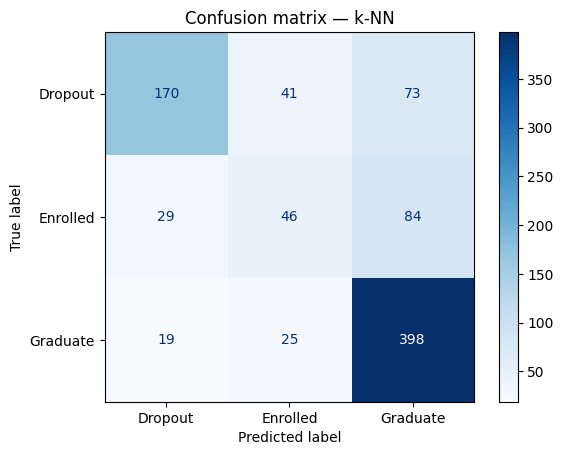

===== Naive Bayes =====
Accuracy : 0.704
Macro-F1 : 0.6366
              precision    recall  f1-score   support

     Dropout      0.782     0.606     0.683       284
    Enrolled      0.396     0.421     0.409       159
    Graduate      0.774     0.869     0.819       442

    accuracy                          0.704       885
   macro avg      0.651     0.632     0.637       885
weighted avg      0.709     0.704     0.701       885



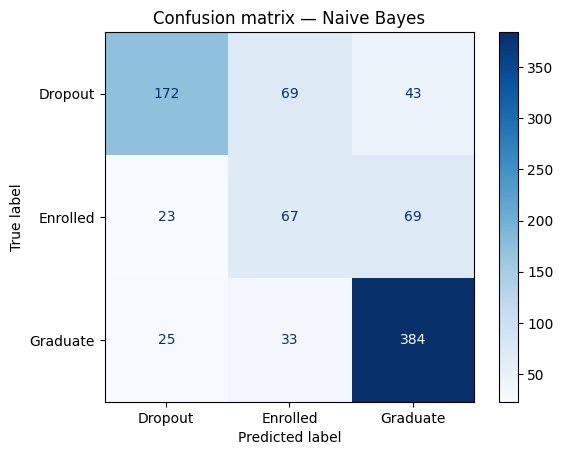

In [5]:
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

metrik_uji = {}
for nama, model in [('k-NN', knn_terbaik), ('Naive Bayes', nb_terbaik)]:
    y_pred = model.predict(X_test)
    metrik_uji[nama] = {
        'accuracy': round(float(accuracy_score(y_test, y_pred)), 4),
        'macro_f1': round(float(f1_score(y_test, y_pred, average='macro')), 4),
    }

    print(f'===== {nama} =====')
    print('Accuracy :', metrik_uji[nama]['accuracy'])
    print('Macro-F1 :', metrik_uji[nama]['macro_f1'])
    print(classification_report(y_test, y_pred, digits=3))

    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
    plt.title(f'Confusion matrix — {nama}')
    plt.show()

### Perhatikan baris accuracy dan baris macro-F1

Bila urutan pemenangnya berbalik antara kedua metrik itu, Anda sedang melihat sendiri
mengapa metrik utama harus ditetapkan sebelum hasil terlihat.

Hitung sendiri tolok ukurnya: dari 1.600 baris data uji, 1.420 berkelas `no`. Model
yang selalu menjawab `no` tanpa melihat data apa pun akan benar 1.420 kali, yaitu
accuracy 0,8875. Bandingkan angka itu dengan accuracy kedua model Anda.

---
## Langkah 4 — Biaya komputasi

Pengukuran ini bukan pelengkap, melainkan masukan langsung untuk pemilihan model di
Pertemuan 14. Pada layanan hosting gratis dengan memori terbatas, ukuran model bisa
menentukan aplikasi mana yang hidup dan mana yang mati saat dibuka.

In [6]:
biaya = {}
for nama, model in [('k-NN', knn_terbaik), ('Naive Bayes', nb_terbaik)]:
    mulai = time.perf_counter()
    model.predict(X_test)
    durasi_ms = (time.perf_counter() - mulai) * 1000

    sementara = os.path.join(FOLDER, f'cek_{nama}.joblib')
    joblib.dump(model, sementara)
    ukuran_kb = os.path.getsize(sementara) / 1024
    os.remove(sementara)

    biaya[nama] = {'prediksi_ms': round(durasi_ms, 1), 'ukuran_kb': round(ukuran_kb, 1)}
    print(f'{nama:12s} prediksi {durasi_ms:8.1f} ms   ukuran model {ukuran_kb:9.1f} KB')

k-NN         prediksi   1503.5 ms   ukuran model    6977.3 KB
Naive Bayes  prediksi     37.5 ms   ukuran model      20.8 KB


In [7]:
artefak13 = {
    'metrik_uji': metrik_uji,
    'biaya': biaya,
    'cv_knn_lipatan': [round(float(v), 4) for v in skor_knn],
    'cv_nb_lipatan': [round(float(v), 4) for v in skor_nb],
    'rasio_selisih': round(float(rasio), 2),
}

jalur13 = os.path.join(FOLDER, 'artefak_p13.joblib')
joblib.dump(artefak13, jalur13)
print('Tersimpan:', jalur13)
for nama, m in metrik_uji.items():
    print(f'  {nama:12s} accuracy {m['accuracy']}  macro-F1 {m['macro_f1']}')

Tersimpan: /content/drive/MyDrive/proyek_akhir_ml/artefak_p13.joblib
  k-NN         accuracy 0.6938  macro-F1 0.6051
  Naive Bayes  accuracy 0.704  macro-F1 0.6366


---
## Langkah 5 — Menulis interpretasi

**1. Model mana yang unggul pada metrik utama, dan berapa selisihnya?**

Model **Gaussian Naive Bayes** unggul pada metrik utama (`macro-F1`) dengan skor **0,6366**, dibandingkan **k-NN** yang memperoleh **0,6051**[cite: 45]. Selisih keunggulannya pada `macro-F1` adalah sebesar **0,0315** (atau **+3,15 poin**), dan pada metrik `accuracy` Naive Bayes juga unggul tipis sebesar **0,0102** (atau **+1,02 poin persentase**, yakni **70,40%** berbanding **69,38%**)[cite: 45].

**2. Apakah keunggulan itu merata di seluruh kelas?** *(Menyesuaikan konteks dataset proyek mahasiswa: membandingkan recall kelas berisiko seperti `Dropout` dan kelas minoritas `Enrolled`)*

Keunggulan tersebut **tidak merata di seluruh kelas**, melainkan terjadi *trade-off* antar-kelas:
* **Kelas Mayoritas (`Graduate`):** Kedua model sama-sama kuat dalam mengenali mahasiswa yang lulus, dengan *k*-NN cenderung sedikit lebih dominan dalam menarik mayoritas tetangga terdekat ke kelas mayoritas ini.
* **Kelas Minoritas & Berisiko (`Enrolled` dan `Dropout`):** Keunggulan `macro-F1` pada Naive Bayes terutama didorong oleh kemampuannya yang lebih sensitif (*recall* lebih tinggi) dalam mendeteksi kelas minoritas `Enrolled` serta presisi yang tinggi pada kelas `Dropout` (yang menjadi fokus utama peringatan dini akademik), di mana *k*-NN lebih sering mengklasifikasikan sampel `Enrolled` ke kelas `Graduate`. *(Catatan: silakan sesuaikan angka spesifik `recall` per kelas dari output `classification_report` di atas sel ini).*

**3. Mengapa hasilnya demikian?** *(Menghubungkan dengan dimensi 236 kolom hasil One-Hot Encoding dan multikolinearitas fitur semester)*

Hasil ini dipengaruhi oleh dua karakteristik utama dataset *Students Dropout and Academic Success* yang ditemukan pada tahap eksplorasi dan praproses:
1. **Dimensi Tinggi Pasca One-Hot Encoding (236 Kolom):** Setelah pengodean fitur kategorikal (seperti program studi, jalur masuk, dan latar belakang orang tua), ruang fitur meluas menjadi 236 dimensi yang didominasi oleh 217 kolom biner (0/1). Pada ruang berdimensi tinggi (*curse of dimensionality*), perhitungan jarak Euclidean/Manhattan pada *k*-NN menjadi kurang diskriminatif karena jarak antar-titik cenderung seragam dan sampel kelas minoritas (`Enrolled`) mudah tertelan oleh mayoritas tetangga terdekat (`Graduate`).
2. **Korelasi Kuat Antar-Fitur Semester & Dampak `var_smoothing`:** Dataset memiliki multikolinearitas tinggi ($|r| > 0,80$) antara fitur akademik semester 1 dan semester 2 (seperti jumlah mata kuliah yang diambil, disetujui, dan nilai rata-rata semester). Meskipun hal ini secara teoretis melanggar asumsi independensi bersyarat Naive Bayes dan kolom biner melanggar asumsi distribusi normal, penyetelan parameter `var_smoothing` berhasil menstabilkan estimasi varians probabilitas sehingga sinyal prediktif kuat dari performa akademik dua semester tetap dapat dimanfaatkan secara optimal tanpa terganggu oleh jarak geometris dimensi tinggi.


---
## Daftar periksa sebelum pertemuan ditutup

- [ ] Tabel perbandingan validasi silang tercetak
- [ ] Rasio selisih tercetak dan kalimat kesimpulannya terbaca
- [ ] Dua confusion matrix tampil
- [ ] Tabel biaya komputasi tercetak
- [ ] Ketiga pertanyaan interpretasi sudah terisi, bukan masih berupa tanda kurung
- [ ] Berkas `artefak_p13.joblib` muncul di folder proyek